In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np

import meep as mp
from meep import mpb

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as colors

import src as mf

# ...
import pythtb as tb

Just a bit of code to make figures more beautiful

In [3]:
mpl.rcParams.update(
    {
        # Figure
        "figure.figsize": (7, 6),  # default figure size in inches, for one-column width
        "figure.dpi": 300,  # higher resolution
        # Font
        "font.family": "serif",  # switch to serif (journal-style)
        "font.size": 11,  # base font size
        "mathtext.fontset": "stix",  # match math to Times-like font
        # Axes
        "axes.labelsize": 11,  # axis label font size
        "axes.titlesize": 12,  # title font size
        "axes.linewidth": 1,  # thickness of axes spines
        # Ticks
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        # Tick length/width
        "xtick.major.size": 4,
        "xtick.major.width": 1,
        "ytick.major.size": 4,
        "ytick.major.width": 1,
        # Grid (off by default, but can be enabled)
        "grid.alpha": 0.3,
        "grid.linestyle": "--",
        # Legend
        "legend.fontsize": 10,
        "legend.frameon": False,
    }
)

## Set-up the model for the numerical simulation

In [44]:
# INPUTS --------------------------------------------------------------------------------- #
NUM_BANDS = 2

EPSILON_INPUT_FILE = "data/kimble/epsilon.h5"

TOLERANCE = 1e-7

N_CELLS = 41  # number of unit cells in each direction

# .. define number of points per direction for the Monkhorst-Pack grid
NK = 64

# angles for the dipole moments of the quantum emitters and its dimensionless value
THETA_1 = (90) * np.pi / 180
THETA_2 = (135) * np.pi / 180
P_DIMLESS = 1e-4

# Position of the quantum emitter in units of the lattice constant 'a'
R0 = [0.0, 0.0]

# small inputs for the tight-binding model
LAT = [[1, 0], [0, 1]]
ORB = [[0, 0]]

BAND_INDEX = 0  # index of the band to consider (0-based)

# coefficients for the tight-binding model
TAU_0 = 0.07755639
TAU_1 = -0.01993698
TAU_2 = 0.00053966

# path in the Brillouin zone for band structure calculation
K_PATH = [[0, 0], [0, 0.5], [0.5, 0.5], [0, 0]]
# define HSPs labels
K_LABEL = [r"$\Gamma$", r"X", r"M", r"$\Gamma$"]

T0 = 0  # initial time for the field snapshots
TF = 20  # final time for the field snapshots
T_STEPS = 100  # number of time steps for the field snapshots
TIME_INDEX = 45  # time index to consider for the field snapshots

# ---------------------------------------------------------------------------------------- #

# Read some data from the epsilon.h5 file
d = mf.read_epsilon_file(EPSILON_INPUT_FILE)
resolution = d["resolution"]
lattice_vecs = d["lattice_vectors"]
lattice_size = d["lattice_size"]

# Print summary of parameters
print("\n")
print("Number of bands      = " + str(NUM_BANDS))
print("Epsilon file used    = " + EPSILON_INPUT_FILE)
print("Resolution           = " + str(resolution))
print("Lattice size         = " + str(lattice_size))
print("Lattice vectors      = " + str(lattice_vecs))
print("Tolerance            = " + str(TOLERANCE))



Number of bands      = 2
Epsilon file used    = data/kimble/epsilon.h5
Resolution           = [64, 64, 1]
Lattice size         = [1, 1, 0]
Lattice vectors      = [[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]]
Tolerance            = 1e-07


## Figure 2

In [5]:
infiniteModel = tb.tb_model(2, 2, LAT, ORB)

# onsite term
infiniteModel.set_onsite([TAU_0])

# 1st nn
infiniteModel.set_hop(TAU_1, 0, 0, [1, 0])
infiniteModel.set_hop(TAU_1, 0, 0, [0, 1])

# 2nd nn
infiniteModel.set_hop(TAU_2, 0, 0, [1, 1])
infiniteModel.set_hop(TAU_2, 0, 0, [1, -1])

In [6]:
# %% Compute bands for the infinite model

### Compute bands along high-symmetry path ...

# creates a path between the HSPs defined before with 500 points between them
k_vec, k_dist, k_node = infiniteModel.k_path(K_PATH, 500, report=False)

# solve the infinite model in the considered path
evals = infiniteModel.solve_all(k_vec)

## .. Select the detuning frequency
# select the emitters detunings, we are picking the value of the frequency at the X point
# where there is the saddle point of the band and a high density of states
detuning_freq = np.sqrt(evals[BAND_INDEX][k_node[1] == k_dist].item())
print(f"Detuning frequency selected at X point: {detuning_freq:.6f} (2πc/a)")

Detuning frequency selected at X point: 0.274587 (2πc/a)


In [40]:
# compute the bands with MPB for comparison

geometry_lattice = mp.Lattice(
    size=lattice_size, basis1=lattice_vecs[0], basis2=lattice_vecs[1]
)

ms = mpb.ModeSolver(
    num_bands=NUM_BANDS,
    resolution=mp.Vector3(*resolution),  # type: ignore[arg-type]
    epsilon_input_file=EPSILON_INPUT_FILE,
    tolerance=TOLERANCE,
    mesh_size=1,
    geometry_lattice=geometry_lattice,
    k_points=mf.array_to_Vector3(k_vec),
)

ms.run_te()

# all frequency bands
freqs = ms.all_freqs

Initializing eigensolver data
Computing 2 bands with 1e-07 tolerance
Working in 2 dimensions.
Grid size is 64 x 64 x 1.
Solving for 2 bands at a time.
Creating Maxwell data...
Mesh size is 1.
Lattice vectors:
     (1, 0, 0)
     (0, 1, 0)
     (0, 0, 1)
Cell volume = 1
Reciprocal lattice vectors (/ 2 pi):
     (1, -0, 0)
     (-0, 1, -0)
     (0, -0, 1)
Geometric objects:
Geometric object tree has depth 1 and 0 object nodes (vs. 0 actual objects)
read in 64x64x1 epsilon-input-file "data/kimble/epsilon.h5"
Initializing epsilon function...
Allocating fields...
Solving for band polarization: te.
Initializing fields to random numbers...
500 k-points
  Vector3<0.0, 0.0, 0.0>
  Vector3<0.0, 0.003424657534246575, 0.0>
  Vector3<0.0, 0.00684931506849315, 0.0>
  Vector3<0.0, 0.010273972602739725, 0.0>
  Vector3<0.0, 0.0136986301369863, 0.0>
  Vector3<0.0, 0.017123287671232876, 0.0>
  Vector3<0.0, 0.02054794520547945, 0.0>
  Vector3<0.0, 0.023972602739726026, 0.0>
  Vector3<0.0, 0.02739726027397

In [8]:
# %% Read epsilon data for plotting
md = mpb.MPBData(rectify=False, periods=2)
d = mf.convert_epsilon("./data/kimble/epsilon.h5", md)

x1 = d["positions-lattice"][:, 0]
y1 = d["positions-lattice"][:, 1]
z1 = d["epsilon_values"]

real part range: 1 .. 4


### Compute the fields for the coupling strength

The fields will be saved under `./data/kimble/fields/`, so no need to execute this section if already done.

In [22]:
# ---------------------------------------------------------------------------
# Load dielectric data from epsilon.h5
# ---------------------------------------------------------------------------
d = mf.read_epsilon_file("./data/kimble/epsilon.h5")
resolution = d["resolution"]
lattice_vecs = d["lattice_vectors"]
lattice_size = d["lattice_size"]

# ---------------------------------------------------------------------------
# Monkhorst–Pack sampling of the Brillouin zone
# ---------------------------------------------------------------------------
Nk = 64  # number of sampling points per reciprocal direction

# Compute reciprocal lattice vectors (without the 2π factor, since MPB expects that)
b1, b2, b3 = mf.find_reciprocal_lattice_vectors(lattice_vecs, twopi=False)

# Generate k-point grid (in lattice coordinates by default)
k_points_array = mf.monkhorst_pack_sampling(N=Nk, b1=b1, b2=b2, coordinates="lattice")

# Convert k-points into Meep/MPB Vector3 objects
k_points = mf.array_to_Vector3(k_points_array)

# ---------------------------------------------------------------------------
# Configure the MPB geometry lattice
# ---------------------------------------------------------------------------
geometry_lattice = mp.Lattice(
    size=lattice_size,
    basis1=lattice_vecs[0],
    basis2=lattice_vecs[1],
    # basis3 omitted for 2D computation; MPB treats it implicitly
)

# ---------------------------------------------------------------------------
# Build the MPB mode solver
# ---------------------------------------------------------------------------
ms = mpb.ModeSolver(
    num_bands=NUM_BANDS,
    resolution=mp.Vector3(*resolution),
    epsilon_input_file="./data/kimble/epsilon.h5",
    mesh_size=1,
    geometry_lattice=geometry_lattice,
    k_points=k_points,
)

# Map all k-points into the first Brillouin zone (important for symmetry)
ms.k_points = [ms.first_brillouin_zone(k) for k in ms.k_points]

# ---------------------------------------------------------------------------
# Field extraction callback
# ---------------------------------------------------------------------------
fields_MPBarr = []


def get_efields(ms, band):
    """
    Extract the electric-field Bloch periodic functions for the given band.
    """
    ms.get_efield(band, bloch_phase=False)
    fields_MPBarr.append(ms.get_bloch_field_point(mp.Vector3(*R0)))


# ---------------------------------------------------------------------------
# Run the MPB simulation (TE modes)
# ---------------------------------------------------------------------------
ms.run_te(mpb.fix_hfield_phase, get_efields)  # ensure consistent phase conventions

Initializing eigensolver data
Computing 2 bands with 1e-07 tolerance
Working in 2 dimensions.
Grid size is 64 x 64 x 1.
Solving for 2 bands at a time.
Creating Maxwell data...
Mesh size is 1.
Lattice vectors:
     (1, 0, 0)
     (0, 1, 0)
     (0, 0, 1)
Cell volume = 1
Reciprocal lattice vectors (/ 2 pi):
     (1, -0, 0)
     (-0, 1, -0)
     (0, -0, 1)
Geometric objects:
Geometric object tree has depth 1 and 0 object nodes (vs. 0 actual objects)
read in 64x64x1 epsilon-input-file "./data/kimble/epsilon.h5"
Initializing epsilon function...
Allocating fields...
Solving for band polarization: te.
Initializing fields to random numbers...
4096 k-points
  Vector3<-0.4921875, -0.4921875, 0.0>
  Vector3<-0.4921875, -0.4765625, 0.0>
  Vector3<-0.4921875, -0.4609375, 0.0>
  Vector3<-0.4921875, -0.4453125, 0.0>
  Vector3<-0.4921875, -0.4296875, 0.0>
  Vector3<-0.4921875, -0.4140625, 0.0>
  Vector3<-0.4921875, -0.3984375, 0.0>
  Vector3<-0.4921875, -0.3828125, 0.0>
  Vector3<-0.4921875, -0.367187

In [34]:
# ---------------------------------------------------------------------------
# Process and reorganize MPB output data
# ---------------------------------------------------------------------------

# Convert MPB results into NumPy arrays
fields_in = np.asarray(fields_MPBarr)  # shape: (Nk, 3) or similar
kpts_in = np.asarray(ms.k_points)  # Meep Vector3 → lattice coords
freqs_in = np.asarray(ms.all_freqs)  # Frequencies for all bands

# Ensure R0 is a 2D array (1 row if single point)
r0pts_in = np.atleast_2d(R0)  # returns array of shape (1,:) if R0 was 1D

# Reorganize the raw MPB output into a structured dictionary
d = mf.arrange_data(
    fields_in=fields_in,
    kpts_in=kpts_in,
    r0pts_in=r0pts_in,
    freqs_in=freqs_in,
    lattice_vecs=lattice_vecs,
)

# Extract cleaned and arranged fields
freqs = d["frequencies"]
Ex = d["Ex"]
Ey = d["Ey"]
Ez = d["Ez"]

kpts = d["kpts-cartesian"]
r0pts = d["r0pts-cartesian"]

# ---------------------------------------------------------------------------
# Package results and save to disk
# ---------------------------------------------------------------------------
output = {
    "freqs": freqs,
    "Ex": Ex,
    "Ey": Ey,
    "Ez": Ez,
    "kpts": kpts,
    "r0pts": r0pts,
}

mf.save(output, filename="64_meshgrid_data.pkl", dirname="./data/kimble/fields/")

### Continue with the plotting

First, we are going to load all the data computed before, so you don't have to compute it everytime.

In [36]:
# ---------------------------------------------------------------------------
# PERFORM THE FOURIER TRANSFORMATION OF THE COUPLING FUNCTION g(r0,r)
# ---------------------------------------------------------------------------

# Load the fields and k-points from the MPB calculation
# This file was generated previously in `kimble.ipynb`
data = mf.load("./data/kimble/fields/64_meshgrid_data.pkl")

# Extract relevant quantities
omegas = np.asarray(data["freqs"])  # Frequencies (Nk, Nb)
Ex = np.asarray(data["Ex"])  # Shape: (Nb, Nk)
Ey = np.asarray(data["Ey"])
Ez = np.asarray(data["Ez"])
kpts = np.asarray(data["kpts"])  # k-points in cartesian coordinates, shape: (Nk, 3)

# Define the dipole moments for the emitters
dipole_moment_1 = P_DIMLESS * np.array([np.cos(THETA_1), np.sin(THETA_1), 0])
dipole_moment_2 = P_DIMLESS * np.array([np.cos(THETA_2), np.sin(THETA_2), 0])

# ---------------------------------------------------------------------------
# Select the band of interest
# ---------------------------------------------------------------------------

E_k_r0 = np.array(
    [Ex[BAND_INDEX, :, :], Ey[BAND_INDEX, :, :], Ez[BAND_INDEX, :, :]]
)  # Shape: (3, Nk, Nb?)
omega_k = omegas[:, BAND_INDEX]  # Shape: (Nk,)

# ---------------------------------------------------------------------------
# Define the real-space grid for interpolation
# ---------------------------------------------------------------------------
xg = np.linspace(-5, 5, 101)
yg = np.linspace(-5, 5, 101)
rpts = mf.meshgrid_points(xg, yg)  # Shape: (Nx*Ny, 2)

# ---------------------------------------------------------------------------
# Compute g(r0,r) for each dipole moment
# ---------------------------------------------------------------------------
gr0r_1 = mf.compute_gr0r(E_k_r0, dipole_moment_1, omega_k, kpts, rpts)
gr0r_2 = mf.compute_gr0r(E_k_r0, dipole_moment_2, omega_k, kpts, rpts)

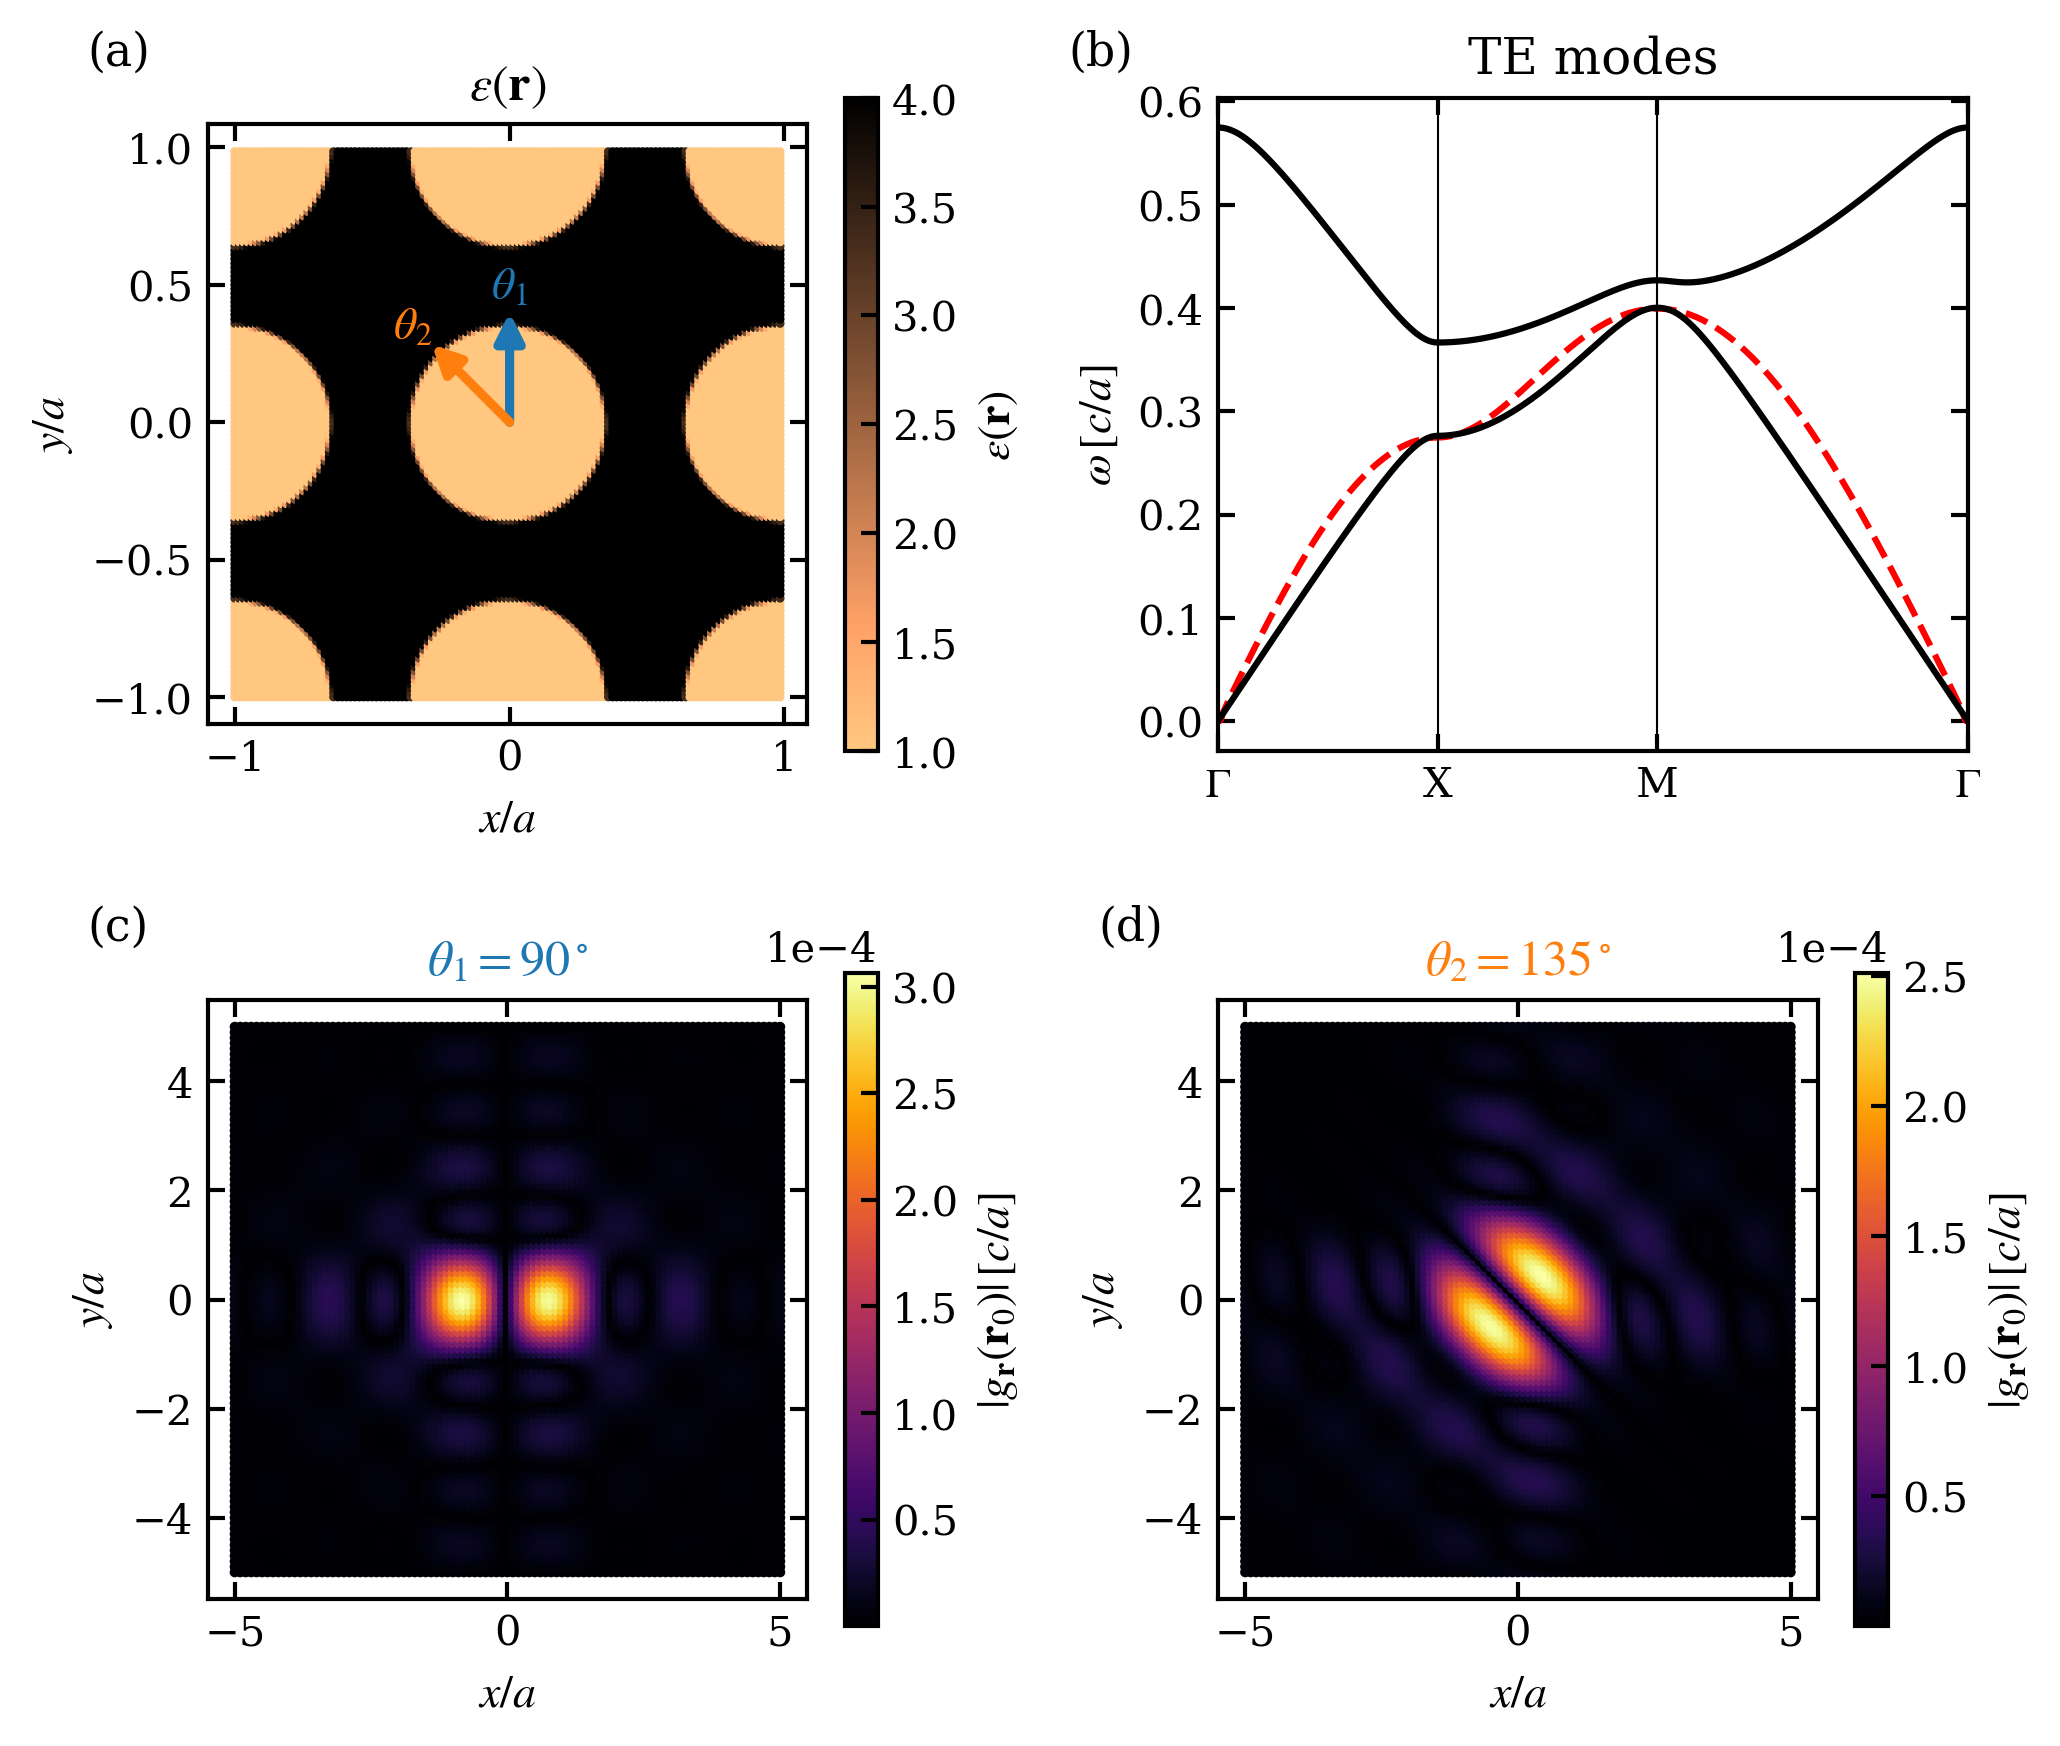

In [64]:
fig, axs = plt.subplots(2, 2)  # two-column width
panel_labels = ["(a)", "(b)", "(c)", "(d)"]

# ----------------------------------------------
# Global dipole settings
# ----------------------------------------------
x0, y0 = R0
dip_colors = ["#1f77b4", "#ff7f0e"]  # [dipole 1, dipole 2]
arrow_length = 0.4

# =====================================================
# --- First quadrant: dielectric structure (a)
# =====================================================
ax = axs[0, 0]
sc1 = ax.scatter(x1, y1, c=z1, marker="o", cmap="copper_r", s=mf.marker_size(len(x1)))
fig.colorbar(sc1, ax=ax, label=r"$\epsilon(\mathbf{r})$")
ax.set_title(r"$\epsilon(\mathbf{r})$")
ax.set_xlabel(r"$x/a$")
ax.set_ylabel(r"$y/a$")
ax.set_aspect("equal")
ax.text(-0.2, 1.1, panel_labels[0], transform=ax.transAxes)

mf.draw_arrow(ax, R0, THETA_1, dip_colors[0], r"$\theta_1$", length=arrow_length)
mf.draw_arrow(ax, R0, THETA_2, dip_colors[1], r"$\theta_2$", length=arrow_length)

# =====================================================
# --- Second quadrant: TE bands (b)
# =====================================================
ax = axs[0, 1]
for n in evals:
    # Ensure no negative values due to numerical errors
    n_safe = np.clip(np.real(n), 0, None)
    ax.plot(k_dist, np.sqrt(n_safe), color="r", linestyle="--")
ax.plot(k_dist, freqs, color="k")
ax.set_xlim(k_node[0], k_node[-1])
ax.set_xticks(k_node)
ax.set_xticklabels(K_LABEL)
for k in k_node:
    ax.axvline(x=k, linewidth=0.5, color="k")
ax.set_ylabel(r"$\omega \, [c/a]$")
ax.set_title("TE modes")
ax.text(-0.2, 1.05, panel_labels[1], transform=ax.transAxes)

# =====================================================
# --- Third quadrant: g(r0,r) dipole 1 (c)
# =====================================================
ax = axs[1, 0]
emitter_indx = 0
sc2 = ax.scatter(
    rpts[:, 0],
    rpts[:, 1],
    c=np.abs(gr0r_1[emitter_indx, :]),  # take absolute value for plotting
    s=mf.marker_size(len(rpts)),
    marker="o",
    cmap="inferno",
)
cbar1 = fig.colorbar(sc2, ax=ax, label=r"$|g_\mathbf{r}(\mathbf{r}_0)| \, [c/a]$")
cbar1.formatter.set_powerlimits((0, 0))  # type: ignore

ax.set_title(
    r"$\theta_1 = {:.0f}^\circ$".format(THETA_1 * 180 / np.pi), color=dip_colors[0]
)
ax.set_xlabel(r"$x/a$")
ax.set_ylabel(r"$y/a$")
ax.set_aspect("equal")
ax.text(-0.2, 1.1, panel_labels[2], transform=ax.transAxes)

# =====================================================
# --- Fourth quadrant: g(r0,r) dipole 2 (d)
# =====================================================
ax = axs[1, 1]
sc3 = ax.scatter(
    rpts[:, 0],
    rpts[:, 1],
    c=np.abs(gr0r_2[emitter_indx, :]),  # take absolute value for plotting
    s=mf.marker_size(len(rpts)),
    marker="o",
    cmap="inferno",
)
cbar2 = fig.colorbar(sc3, ax=ax, label=r"$|g_\mathbf{r}(\mathbf{r}_0)| \, [c/a]$")
cbar2.formatter.set_powerlimits((0, 0))  # type: ignore

ax.set_title(
    r"$\theta_2 = {:.0f}^\circ$".format(THETA_2 * 180 / np.pi), color=dip_colors[1]
)
ax.set_xlabel(r"$x/a$")
ax.set_ylabel(r"$y/a$")
ax.set_aspect("equal")
ax.text(-0.2, 1.1, panel_labels[3], transform=ax.transAxes)

# --- Layout and save ---
fig.tight_layout()
fig.savefig("./figures/paper_figure_2.svg", dpi=300)
plt.show()

In [80]:
detuning_freq

np.float64(0.27458650731600054)

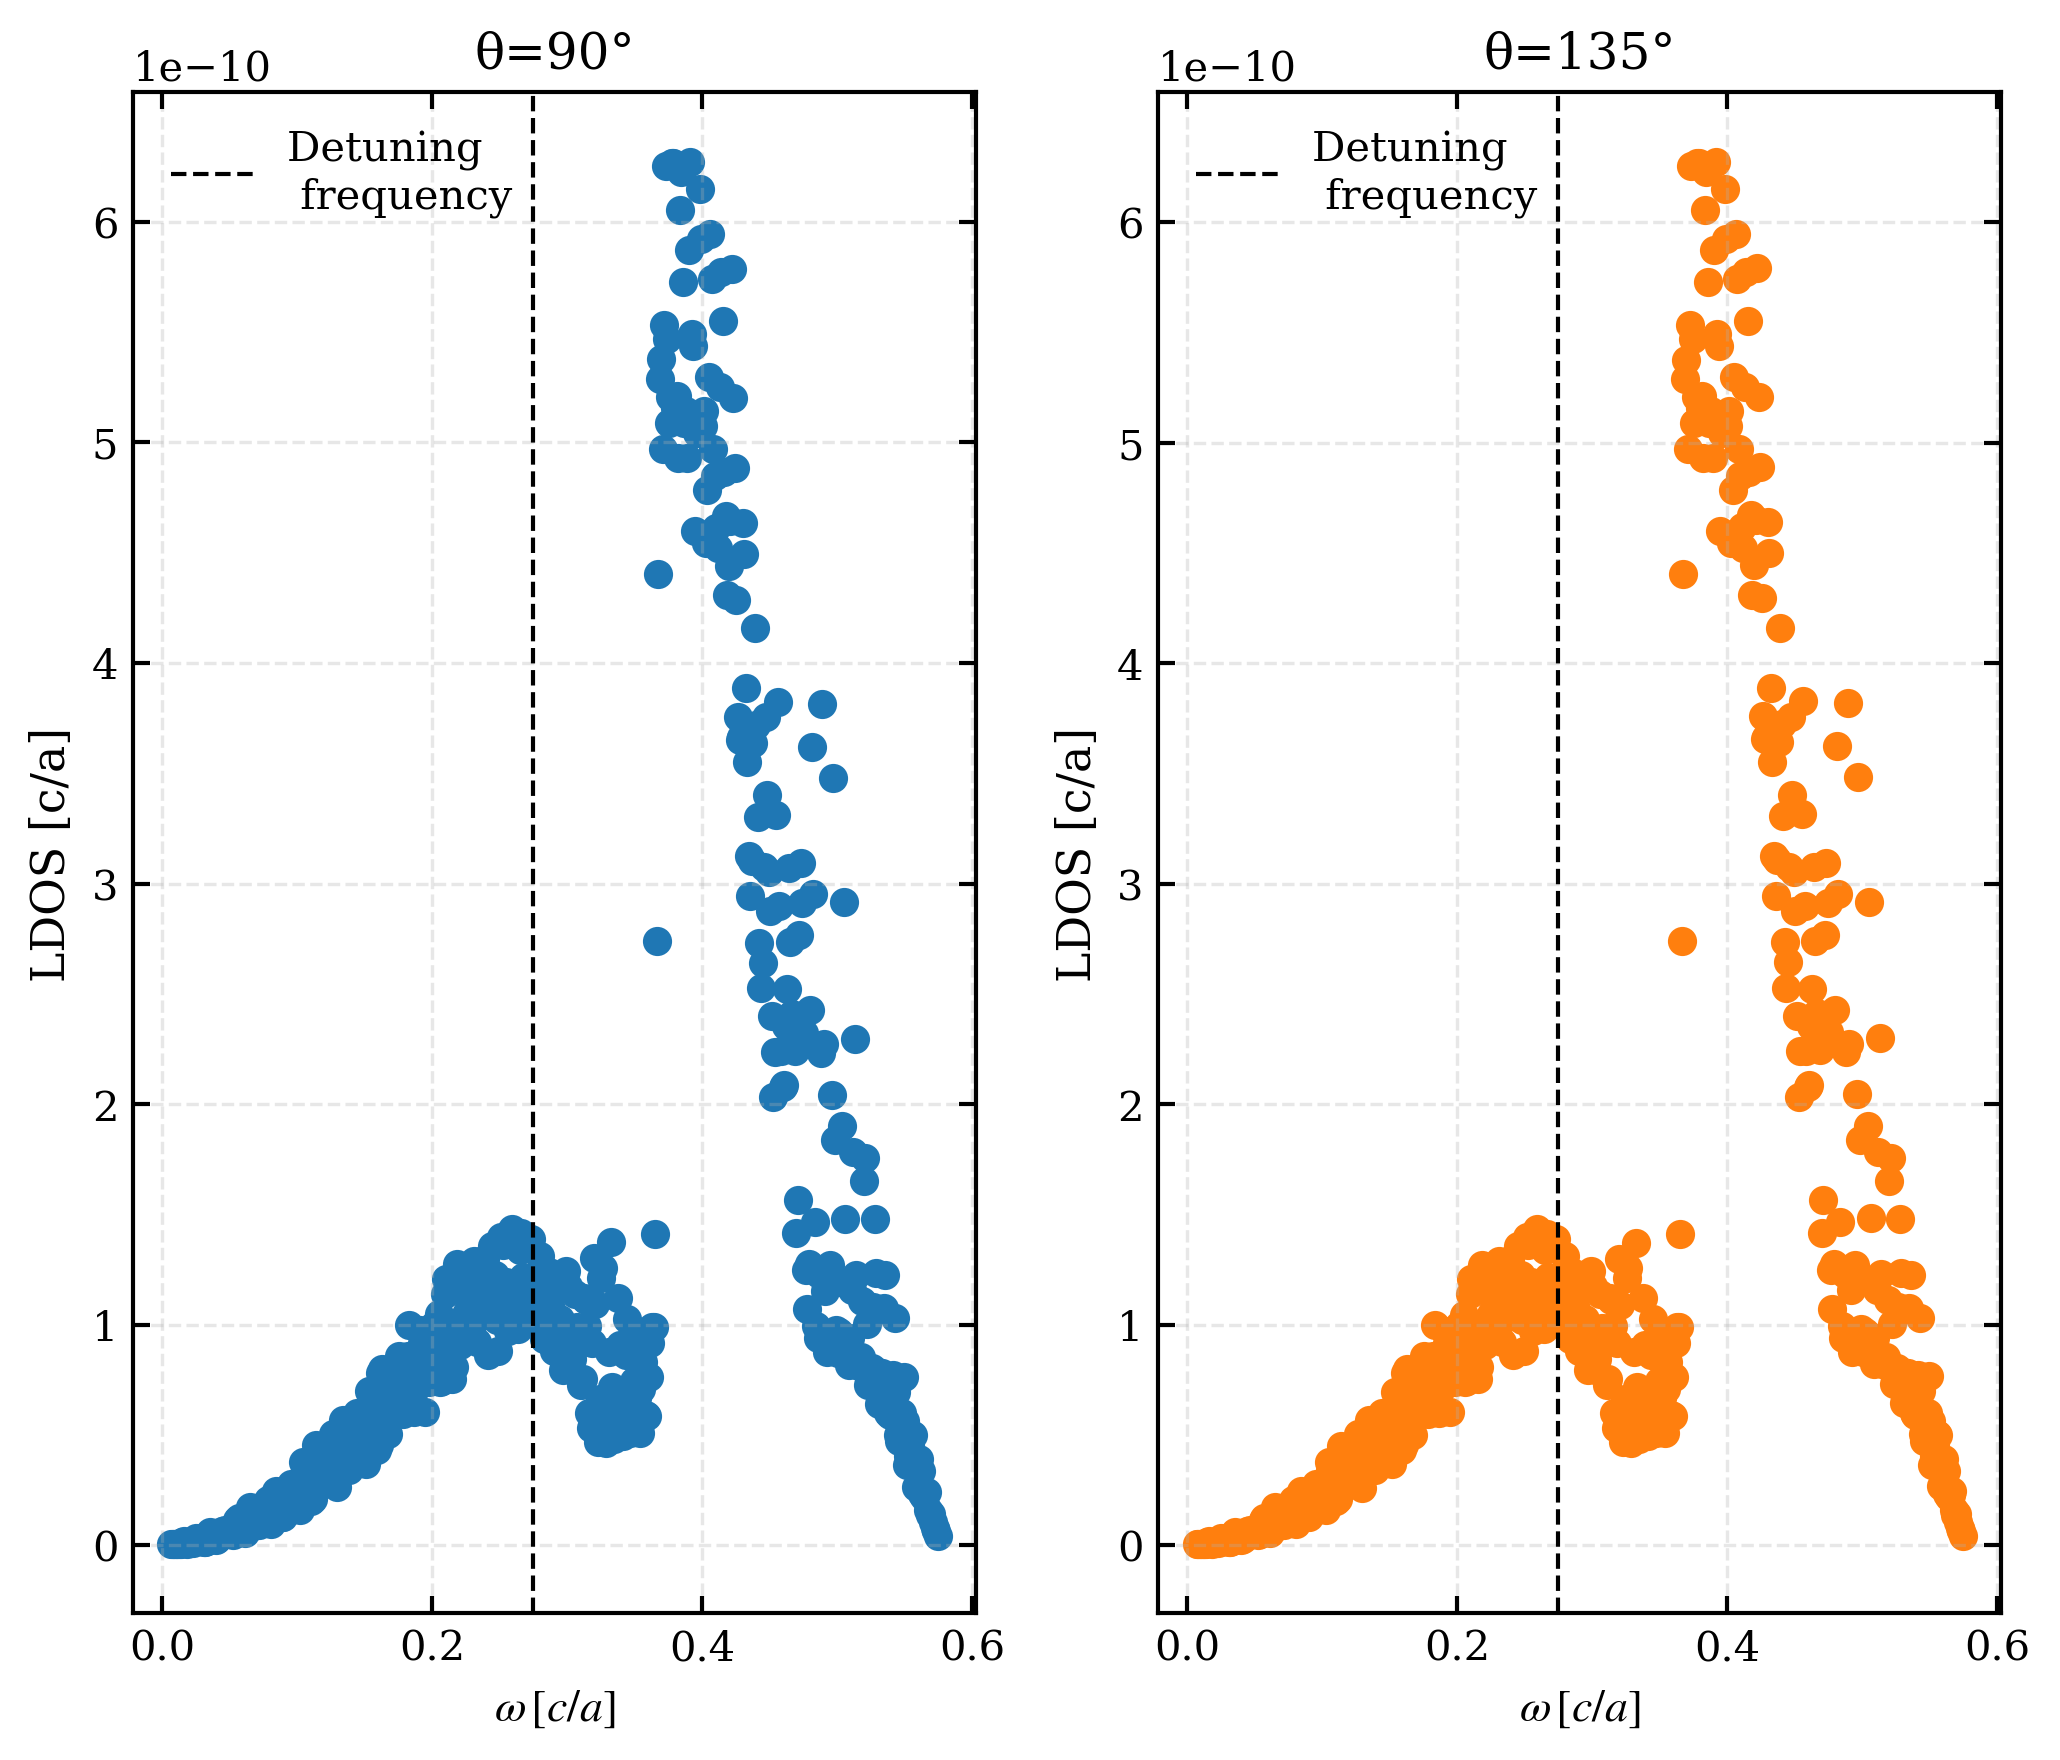

In [84]:
# -----------------------------
# Define dipoles
# -----------------------------
thetas = [THETA_1, THETA_2]
dipoles = [P_DIMLESS * np.array([np.cos(theta), np.sin(theta), 0]) for theta in thetas]
dip_colors = ["#1f77b4", "#ff7f0e"]  # colors for each dipole

# Frequency range for LDOS
omega_eval = np.linspace(np.min(omegas), np.max(omegas), 500)

# Fields for the selected band
E_k_r0 = np.moveaxis(np.squeeze(np.array([Ex, Ey, Ez])), 0, -1)
# Now shape = (Nb, Nk, 3). If needed:
E_k_r0 = np.swapaxes(E_k_r0, 0, 1)  # final: (Nk, Nb, 3)

omega_k = omegas

# -----------------------------
# Compute LDOS for each dipole
# -----------------------------
ldos_list = [
    mf.compute_ldos(omega_eval=omega_eval, omega_k=omega_k, E_k_r0=E_k_r0, p_vec=dip)
    for dip in dipoles
]

# -----------------------------
# Plot LDOS side by side
# -----------------------------
fig, axs = plt.subplots(1, 2)

for i, ax in enumerate(axs):
    ax.scatter(omega_eval, ldos_list[i], color=dip_colors[i])
    ax.set_xlabel(r"$\omega \, [c/a]$")
    ax.set_ylabel("LDOS [c/a]")
    ax.set_title(f"θ={np.degrees(thetas[i]):.0f}°")
    ax.grid(True)
    ax.axvline(
        x=detuning_freq,
        color="k",
        linestyle="--",
        label="Detuning \n frequency",
        linewidth=1,
    )
    ax.legend()

fig.tight_layout()
plt.show()

## Figure 3

In [23]:
alpha_norm = TAU_0 / np.abs(TAU_1)
j1_norm = TAU_1 / np.abs(TAU_1)
j2_norm = TAU_2 / np.abs(TAU_1)

infiniteModel = tb.tb_model(2, 2, LAT, ORB)

# onsite term
infiniteModel.set_onsite([alpha_norm])

# 1st nn
infiniteModel.set_hop(j1_norm, 0, 0, [1, 0])
infiniteModel.set_hop(j1_norm, 0, 0, [0, 1])

# 2nd nn
infiniteModel.set_hop(j2_norm, 0, 0, [1, 1])
infiniteModel.set_hop(j2_norm, 0, 0, [1, -1])

In [24]:
# --- Generate k-point grid in the 2D Brillouin zone ---
# Assuming square BZ [-0.5, 0.5) x [-0.5, 0.5) in reciprocal coords
kx = np.linspace(-0.5, 0.5, NK)
ky = np.linspace(-0.5, 0.5, NK)
kx_grid, ky_grid = np.meshgrid(kx, ky)

# --- Compute band energies ---
omega = np.zeros_like(kx_grid)
for i in range(NK):
    for j in range(NK):
        kvec = [kx_grid[i, j], ky_grid[i, j]]
        evals = infiniteModel.solve_one(kvec)  # PythTB band energies at k
        omega[i, j] = evals[BAND_INDEX]

In [25]:
# load the data from a file
data_fields = mf.load("./data/kimble/Nk64/MPB_output.pkl")
Ex = data["Ex"]
Ey = data["Ey"]
Ez = data["Ez"]
kpts = data["kpts"]

# .. Select the dipole moment
dipole_moment_1 = np.array([np.cos(THETA_1), np.sin(THETA_1), 0])
dipole_moment_2 = np.array([np.cos(THETA_2), np.sin(THETA_2), 0])

# .. Define the fields of the selected band
E_band = [Ex[BAND_INDEX, :, :], Ey[BAND_INDEX, :, :], Ez[BAND_INDEX, :, :]]

# %% Finite model definition

# Cut the system
temporalModel = infiniteModel.cut_piece(
    N_CELLS, fin_dir=0, glue_edgs=False
)  # cutout along 1st direction
finiteModel = temporalModel.cut_piece(
    N_CELLS, fin_dir=1, glue_edgs=False
)  # cutout along 2nd direction

# Let me recalculate the coupling accordingly with the system's size.
# NOTE: the indexing is now "xy" so that the ordering of rjpts coincides with the one created by pythonTB

if N_CELLS % 2 == 0:
    xjg = np.arange(-N_CELLS / 2, N_CELLS / 2, 1)
    yjg = np.arange(-N_CELLS / 2, N_CELLS / 2 + 1, 1)
else:
    xjg = np.arange(-(N_CELLS // 2), N_CELLS // 2 + 1, 1)
    yjg = np.arange(-(N_CELLS // 2), N_CELLS // 2 + 1, 1)
rjpts = mf.meshgrid_points(xjg, yjg, indexing="xy")

gr0rj_1 = mf.compute_gr0r(E_band, dipole_moment_1, detuning_freq, kpts, rjpts)
gr0rj_1_norm = gr0rj_1 / np.sqrt(np.abs(TAU_1))  # normalize to |t1|^{1/2}
gr0rj_2 = mf.compute_gr0r(E_band, dipole_moment_2, detuning_freq, kpts, rjpts)
gr0rj_2_norm = gr0rj_2 * np.sqrt(np.abs(TAU_1))  # normalize to |t1|^{1/2}
# TODO: check normalization here, does it make sense?

# %% Build the light-matter Hamiltonian

# ... non-local couplings
values_1 = gr0rj_1_norm[BAND_INDEX, :]
values_2 = gr0rj_2_norm[BAND_INDEX, :]

# small check before proceeding
assert len(values_1) == len(values_2), "Unexpected different lengths for the couplings!"

indexes = np.arange(0, len(gr0rj_1[0, :]), 1)
couplings_1 = [[list(values_1), list(indexes)]]
couplings_2 = [[list(values_2), list(indexes)]]

# build the light-matter Hamiltonian
H_total_1 = mf.make_light_matter_Hamiltonian(finiteModel, detuning_freq, couplings_1)
H_total_2 = mf.make_light_matter_Hamiltonian(finiteModel, detuning_freq, couplings_2)

# %% Compute time evolution

from scipy.sparse.linalg import expm_multiply

tvals = np.linspace(T0, TF, T_STEPS)

# Define initial condition
assert np.shape(H_total_1) == np.shape(
    H_total_2
), "Unexpected different shapes for the Hamiltonians!"
psi0 = np.zeros(np.shape(H_total_1)[0])
psi0[0] = 1

# Compute time evolution
psit_1 = expm_multiply(-1j * H_total_1, psi0, T0, TF, T_STEPS, endpoint=True)
psit_2 = expm_multiply(-1j * H_total_2, psi0, T0, TF, T_STEPS, endpoint=True)

ValueError: Sparse arrays/matrices are not supported by this function. Perhaps one of the `scipy.sparse.linalg` functions would work instead.

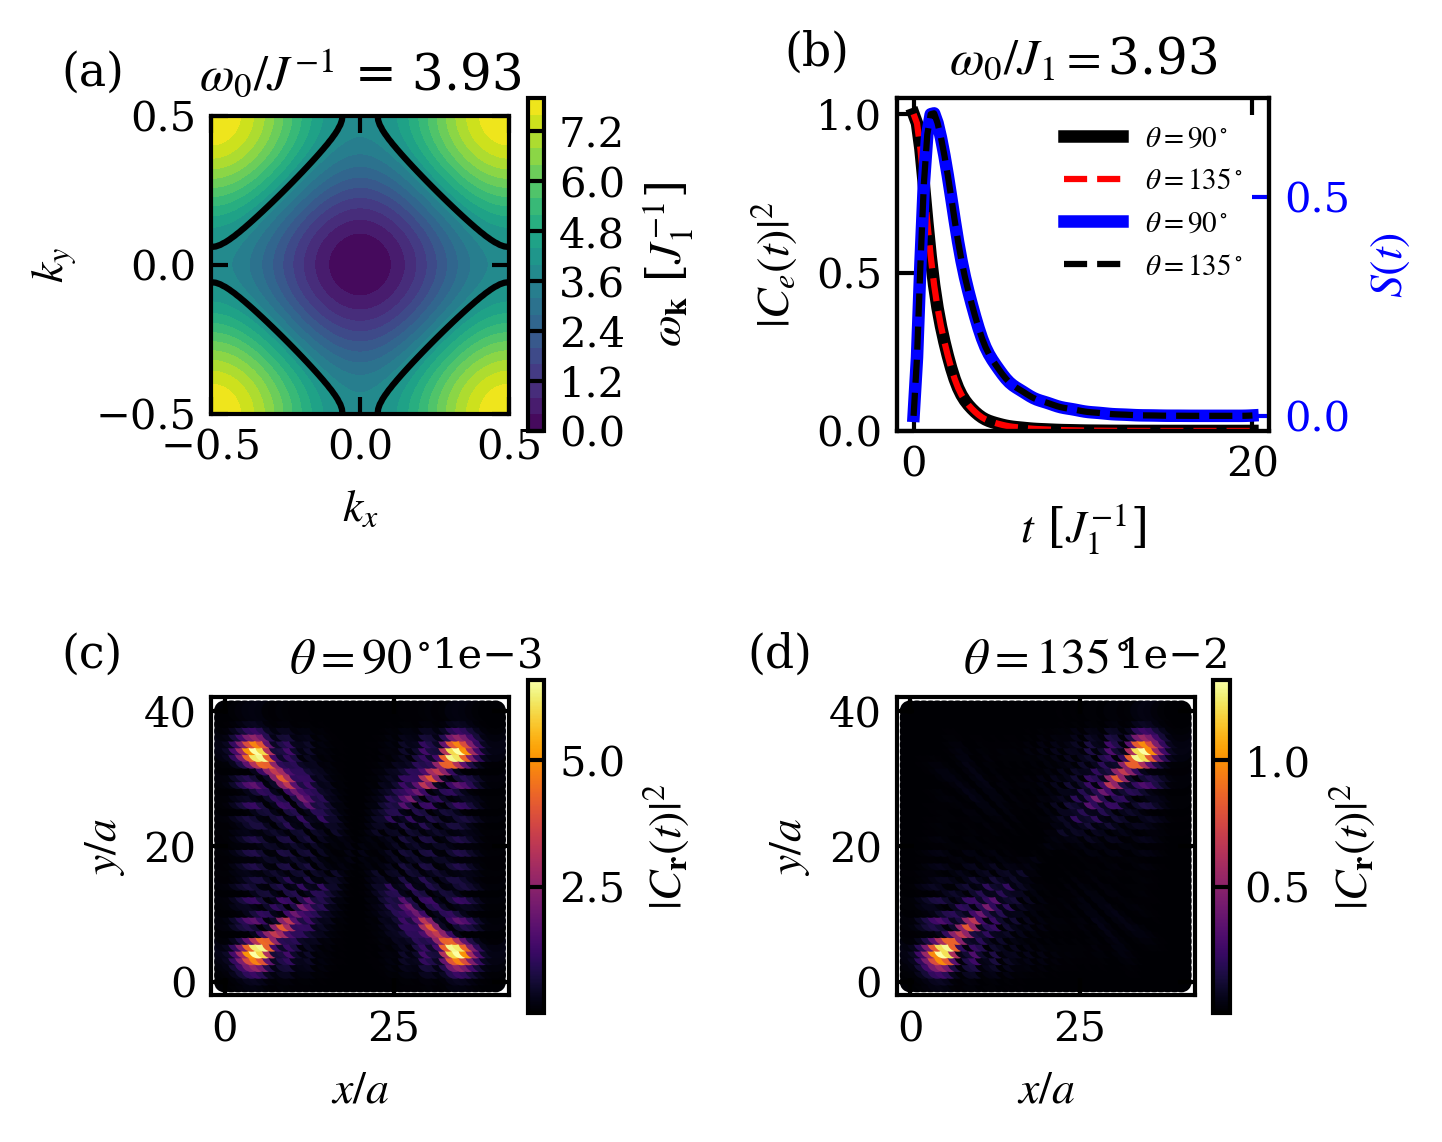

In [17]:
# --- Plotting ---
fig, axs = plt.subplots(2, 2, figsize=(5, 4))

panel_labels = ['(a)', '(b)', '(c)', '(d)']

# Filled contour of band dispersion in the first quadrant
ax = axs[0,0]
c = ax.contourf(kx_grid, ky_grid, omega, levels=20, cmap="viridis")
fig.colorbar(c, ax=ax, label=r"$\omega_\mathbf{k}$ [$J_1^{-1}$]")

# Isofrequency contour at the emitter frequency
ax.contour(kx_grid, ky_grid, omega, levels=[detuning_freq], colors="black", linewidths=1.5)

ax.set_xlabel(r"$k_x$")
ax.set_ylabel(r"$k_y$")
ax.set_title(r"$\omega_0/J^{-1}$ = " + f"%.2f" % detuning_freq)
ax.set_aspect("equal")
ax.text(-0.5, 1.1, panel_labels[0], transform=ax.transAxes)

# %% Plot emitter's dynamics

# Prepare data to be plotted ...

# get emitter component of the overall wavefunction
mod_Ce_squared_1 = np.abs(psit_1[:, 0]) ** 2
mod_Ce_squared_2 = np.abs(psit_2[:, 0]) ** 2

# compute the entanglement for both cases
entropy_1 = mf.binary_entropy(mod_Ce_squared_1)
entropy_2 = mf.binary_entropy(mod_Ce_squared_2)

# --- plotting ---
ax1 = axs[0,1]

# left y-axis: population
l1, = ax1.plot(tvals, mod_Ce_squared_1, lw=3, c="k", label=r"$\theta=90^\circ$")
l2, = ax1.plot(tvals, mod_Ce_squared_2, c="r", ls="--", label=r"$\theta=135^\circ$")
ax1.set_xlabel(r"$t$ [$J_1^{-1}$]")
ax1.set_ylabel(r"$|C_e(t)|^2$")
ax1.set_ylim([0, 1.05])

# right y-axis: entropy
ax2 = ax1.twinx()
l3, = ax2.plot(tvals, entropy_1, c="b", lw=3, label=r"$\theta=90^\circ$")
l4, = ax2.plot(tvals, entropy_2, c="k", ls="--", label=r"$\theta=135^\circ$")
ax2.set_ylabel(r"$S(t)$", color="b")
ax2.tick_params(axis="y", colors="b")

# combine legends
lines = [l1, l2, l3, l4]
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="best", fontsize=7)

# title
ax1.set_title(r"$\omega_0/J_1 = $" + f"%.2f" % detuning_freq)
ax1.text(-0.3, 1.1, panel_labels[1], transform=ax1.transAxes)

# get positions in Cartesian coordinates (requires find_positions() defined above)
positions = mf.find_positions(finiteModel._orb, finiteModel._lat)

# get photonic component of the overall wave function at selected time, i.e, tvals[time_index]
mod_Cr_squared_1 = np.abs(psit_1[TIME_INDEX, 1 : np.shape(psit_1)[1]]) ** 2
mod_Cr_squared_2 = np.abs(psit_2[TIME_INDEX, 1 : np.shape(psit_2)[1]]) ** 2

x = positions[:, 0]
y = positions[:, 1]
z1 = mod_Cr_squared_1
z2 = mod_Cr_squared_2

# Plot figure ...
ax = axs[1,0]

# scatter plot
sc = ax.scatter(x, y, c=z1, s=mf.marker_size(len(x)), marker="o", cmap="inferno")

# axis properties
ax.set(xlabel=r"$x/a$", ylabel=r"$y/a$", title=r"$\theta=90^\circ$")
ax.set_aspect("equal")
ax.text(-0.5, 1.1, panel_labels[2], transform=ax.transAxes)

# colorbar
cbar = fig.colorbar(sc, ax=ax)
cbar.formatter.set_powerlimits((0, 0))
cbar.set_label(r"$|C_\mathbf{r}(t)|^2$")

# Plot figure ...
ax = axs[1,1]

# scatter plot
sc = ax.scatter(x, y, c=z2, s=mf.marker_size(len(x)), marker="o", cmap="inferno")

# axis properties
ax.set(xlabel=r"$x/a$", ylabel=r"$y/a$", title=r"$\theta=135^\circ$")
ax.set_aspect("equal")
ax.text(-0.5, 1.1, panel_labels[3], transform=ax.transAxes)

# colorbar
cbar = plt.colorbar(sc, ax=ax)
cbar.formatter.set_powerlimits((0, 0))
cbar.set_label(r"$|C_\mathbf{r}(t)|^2$")

fig.tight_layout(pad=1.0)
fig.savefig("./figures/paper_figure_3.svg")